# Hybrid CNN-LSTM Model for Short-Term Solar Power Forecasting with Anomaly-Aware Preprocessing

**Target Conference:** ICSPER 2026  
**Dataset:** NREL Solar Power Data for Integration Studies (SQLite: `solar_data`)  
**Facility:** 70 MW Utility Photovoltaic (UPV) Plant (Lat: 30.45, Lon: -88.25)  
**Resolution:** 5-Minute Sampling Interval (105,120 continuous observations, full year 2006)  
**Forecast Horizon:** $H=6$ steps ahead (30 minutes ahead, sub-hour economic dispatch interval)  
**Statistical Rigor:** 5-Seed Evaluation (`seeds = [42, 123, 7, 2024, 99]`) across all Deep Learning Models + Paired Significance Testing  

This notebook provides the complete, self-contained, reproducible research pipeline covering:
1. SQLite Telemetry Querying & Site Filtering
2. Cyclical Astronomical Feature Engineering (Hour/Day Sin & Cos)
3. Realistic Synthetic Sensor Degradation (~2% Dropouts, Spikes, Calibration Drifts)
4. Unsupervised Outlier Detection via **Isolation Forest** & Local Linear Temporal Reconstruction
5. Sliding Window Formulation ($W=24$ past steps / 2 hrs $\to H=6$ ahead steps / 30 min)
6. Benchmark Reference Conditions: **Run A (Pristine Ceiling)** & **Run B (Oracle Imputation Bound)**
7. Deep Learning & Classical Model Architectures: Persistence, Autoregressive / ARIMA, Plain LSTM, Hybrid CNN-LSTM
8. Full PyTorch Model Training over 5 Seeds & Comprehensive 7-Condition Benchmark Suite
9. Rigorous Statistical Evaluation (Mean ± Std, Signal Recovery %, Paired Student's t-test)
10. High-Resolution Publication Figures with Multi-Seed Error Bars (Figures 1 to 4)

In [1]:
import sys
import os
user_site = r'C:\Users\TUSHAR BASAK\AppData\Roaming\Python\Python314\site-packages'
if os.path.exists(user_site) and user_site not in sys.path:
    sys.path.insert(0, user_site)

import sqlite3
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Base reproducibility seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

Using compute device: cpu


## Step 1: Load Data & Select One Site
Connect to SQLite database and query data for a single site (`latitude=30.45, longitude=-88.25, site_type='UPV', resolution='5_Min'`) to prevent spatial mixing.

In [2]:
db_path = 'solar_data.db'
conn = sqlite3.connect(db_path)
query = """
SELECT datetime, power_mw, capacity_mw
FROM solar_data
WHERE latitude = 30.45 AND longitude = -88.25
  AND site_type = 'UPV' AND resolution = '5_Min'
ORDER BY datetime ASC;
"""
df = pd.read_sql_query(query, conn)
conn.close()

df['datetime'] = pd.to_datetime(df['datetime'])
print(f"Loaded {len(df):,} observations for single UPV site.")
print(f"Time span: {df['datetime'].min()} to {df['datetime'].max()}")
print(f"Nameplate Capacity: {df['capacity_mw'].iloc[0]} MW")
df.head()

Loaded 105,120 observations for single UPV site.
Time span: 2006-01-01 00:00:00 to 2006-12-31 23:55:00
Nameplate Capacity: 70 MW


,datetime,power_mw,capacity_mw
0,2006-01-01 00:00:00,0.0,70
1,2006-01-01 00:05:00,0.0,70
2,2006-01-01 00:10:00,0.0,70
3,2006-01-01 00:15:00,0.0,70
4,2006-01-01 00:20:00,0.0,70


## Step 2: Feature Engineering (Cyclical Encoding)
Solar generation exhibits strict diurnal and seasonal cyclicity. Transform timestamps into sine/cosine harmonic pairs:

In [3]:
minute_of_day = df['datetime'].dt.hour * 60 + df['datetime'].dt.minute
df['hour_sin'] = np.sin(2 * np.pi * minute_of_day / 1440.0)
df['hour_cos'] = np.cos(2 * np.pi * minute_of_day / 1440.0)
day_of_year = df['datetime'].dt.dayofyear
df['day_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
df['day_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
print("Engineered 4 cyclical features: ['hour_sin', 'hour_cos', 'day_sin', 'day_cos']")

Engineered 4 cyclical features: ['hour_sin', 'hour_cos', 'day_sin', 'day_cos']


## Step 3: Controlled Synthetic Anomaly Injection
Inject physical sensor failure modes across ~2% of telemetry (2,091 rows):
- **Dropouts:** Forced zero during daylight hours ($P > 5$ MW).
- **Spikes:** 3x - 5x multiplication (inverter transients / bit flips).
- **Drift:** Consecutive blocks with additive offset (pyranometer dust / thermal drift).

In [4]:
np.random.seed(SEED)
df['power_raw'] = df['power_mw'].copy()
df['is_anomaly'] = 0
n_total = len(df)
n_target = int(n_total * 0.02)
n_per_type = n_target // 3
capacity = float(df['capacity_mw'].iloc[0])

# 1. Dropouts
daylight_idx = df[df['power_mw'] > 5.0].index.values
drop_idx = np.random.choice(daylight_idx, size=n_per_type, replace=False)
df.loc[drop_idx, 'power_raw'] = 0.0
df.loc[drop_idx, 'is_anomaly'] = 1

# 2. Spikes
spike_cand = df[(df['power_mw'] > 2.0) & (df['is_anomaly'] == 0)].index.values
spike_idx = np.random.choice(spike_cand, size=n_per_type, replace=False)
mult = np.random.uniform(3.0, 5.0, size=len(spike_idx))
df.loc[spike_idx, 'power_raw'] = np.clip(df.loc[spike_idx, 'power_raw'] * mult, 0, capacity * 1.5)
df.loc[spike_idx, 'is_anomaly'] = 2

# 3. Calibration Drift
clean_cand = df[df['is_anomaly'] == 0].index.values
drift_cnt = 0
while drift_cnt < n_per_type and len(clean_cand) > 10:
    st = np.random.choice(clean_cand)
    blen = np.random.randint(4, 12)
    bidx = np.arange(st, min(st + blen, n_total))
    offset = np.random.uniform(0.15 * capacity, 0.35 * capacity)
    df.loc[bidx, 'power_raw'] += offset
    df.loc[bidx, 'is_anomaly'] = 3
    drift_cnt += len(bidx)
    clean_cand = np.setdiff1d(clean_cand, bidx)

tot_anom = (df['is_anomaly'] > 0).sum()
print(f"Injected {tot_anom} anomalies ({tot_anom/n_total*100:.2f}% of series):")
print(f"  - Dropouts: {(df['is_anomaly']==1).sum()} rows")
print(f"  - Spikes:   {(df['is_anomaly']==2).sum()} rows")
print(f"  - Drifts:   {(df['is_anomaly']==3).sum()} rows")

Injected 2091 anomalies (1.99% of series):
  - Dropouts: 695 rows
  - Spikes:   698 rows
  - Drifts:   698 rows


## Step 4: Outlier Mitigation (Isolation Forest vs. Oracle Ground-Truth)
Train an unsupervised **Isolation Forest** on `[power_raw, hour_sin, hour_cos]` to flag anomalous points ($s(x) > \tau$) and reconstruct via local linear interpolation.
Concurrently, generate `power_oracle_cleaned` using ground-truth injected labels (`is_anomaly > 0`) to establish the **Run B Oracle Imputation Bound**.

In [5]:
X_if = df[['power_raw', 'hour_sin', 'hour_cos']].values
iso = IsolationForest(contamination=0.025, random_state=SEED, n_estimators=100)
preds = iso.fit_predict(X_if)
df['detected_outlier'] = (preds == -1).astype(int)

# Unsupervised Proposed Cleaning: Linear interpolation on detected outliers
df['power_cleaned'] = df['power_raw'].copy()
df.loc[df['detected_outlier'] == 1, 'power_cleaned'] = np.nan
df['power_cleaned'] = df['power_cleaned'].interpolate(method='linear').bfill().ffill()
df['power_cleaned'] = np.clip(df['power_cleaned'], 0, capacity)

# Oracle Cleaned: Linear interpolation strictly on ground-truth anomalies (Run B)
df['power_oracle_cleaned'] = df['power_raw'].copy()
df.loc[df['is_anomaly'] > 0, 'power_oracle_cleaned'] = np.nan
df['power_oracle_cleaned'] = df['power_oracle_cleaned'].interpolate(method='linear').bfill().ffill()
df['power_oracle_cleaned'] = np.clip(df['power_oracle_cleaned'], 0, capacity)

tp = ((df['is_anomaly'] > 0) & (df['detected_outlier'] == 1)).sum()
fp = ((df['is_anomaly'] == 0) & (df['detected_outlier'] == 1)).sum()
fn = ((df['is_anomaly'] > 0) & (df['detected_outlier'] == 0)).sum()
prec = tp / (tp + fp)
rec = tp / (tp + fn)
print(f"Isolation Forest Detection Evaluation:")
print(f"  - Total Flagged Outliers: {df['detected_outlier'].sum()}")
print(f"  - Precision: {prec:.4f}")
print(f"  - Recall:    {rec:.4f}")
print("Reconstructed both 'power_cleaned' (Proposed) and 'power_oracle_cleaned' (Oracle Bound).")

Isolation Forest Detection Evaluation:
  - Total Flagged Outliers: 2627
  - Precision: 0.5748
  - Recall:    0.7221
Reconstructed both 'power_cleaned' (Proposed) and 'power_oracle_cleaned' (Oracle Bound).


## Step 5: Sliding Sequence Windowing ($W = 24, H = 6$)
Partition the 1-year series chronologically (70% Train, 15% Val, 15% Test) without data leakage.
Construct sequence windows: Past 24 steps (2 hours) $\to$ Predict $H=6$ steps ahead (30 minutes ahead) across all 4 data conditions:
- **Pristine Clean Telemetry (`power_mw`):** Theoretical Ceiling (Run A)
- **Oracle Cleaned Telemetry (`power_oracle_cleaned`):** Imputation Upper Bound (Run B)
- **Proposed Cleaned Telemetry (`power_cleaned`):** Isolation Forest Pipeline
- **Raw Corrupted Telemetry (`power_raw`):** Ablation Baseline

In [6]:
n_samples = len(df)
train_end = int(n_samples * 0.70)
val_end = int(n_samples * 0.85)

def build_windowed_dataset(target_col, window_size=24, horizon=6):
    feature_cols = [target_col, 'hour_sin', 'hour_cos', 'day_sin', 'day_cos']
    arr = df[feature_cols].values
    scaler = MinMaxScaler()
    train_s = scaler.fit_transform(arr[:train_end])
    val_s = scaler.transform(arr[train_end:val_end])
    test_s = scaler.transform(arr[val_end:])
    full_s = np.vstack([train_s, val_s, test_s])
    
    X, y = [], []
    for i in range(len(full_s) - window_size - horizon + 1):
        X.append(full_s[i : i + window_size])
        y.append(full_s[i + window_size + horizon - 1, 0])
    X, y = np.array(X), np.array(y)
    
    n_win = len(X)
    tr_end = int(n_win * 0.70)
    v_end = int(n_win * 0.85)
    
    return {
        'X_train': X[:tr_end], 'y_train': y[:tr_end],
        'X_val': X[tr_end:v_end], 'y_val': y[tr_end:v_end],
        'X_test': X[v_end:], 'y_test': y[v_end:],
        'p_min': scaler.data_min_[0], 'p_max': scaler.data_max_[0]
    }

data_clean = build_windowed_dataset('power_cleaned', window_size=24, horizon=6)
data_raw = build_windowed_dataset('power_raw', window_size=24, horizon=6)
data_ora = build_windowed_dataset('power_oracle_cleaned', window_size=24, horizon=6)
data_pris = build_windowed_dataset('power_mw', window_size=24, horizon=6)

print(f"Sequence windowing complete (W=24, H=6):")
print(f"  - Train Windows: {data_clean['X_train'].shape}")
print(f"  - Val Windows:   {data_clean['X_val'].shape}")
print(f"  - Test Windows:  {data_clean['X_test'].shape}")

Sequence windowing complete (W=24, H=6):
  - Train Windows: (73563, 24, 5)
  - Val Windows:   (15764, 24, 5)
  - Test Windows:  (15764, 24, 5)


## Step 6: Model Architectures
- **Plain LSTM:** 2-layer stacked LSTM recurrent baseline ($d_h = 64$).
- **Hybrid CNN-LSTM:** 1D-CNN feature extractor ($k=3, \text{filters}=64$) + 2-layer LSTM ($d_h=64$) + Dense projection head.

In [7]:
class PlainLSTM(nn.Module):
    def __init__(self, input_dim=5, hidden_dim=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Sequential(nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

class HybridCNNLSTM(nn.Module):
    def __init__(self, input_dim=5, conv_filters=64, kernel_size=3, hidden_dim=64, num_layers=2):
        super().__init__()
        self.conv1d = nn.Sequential(
            nn.Conv1d(input_dim, conv_filters, kernel_size=kernel_size, padding=kernel_size//2),
            nn.BatchNorm1d(conv_filters),
            nn.ReLU()
        )
        self.lstm = nn.LSTM(conv_filters, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Sequential(nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        x = x.transpose(1, 2) # (B, F, W)
        conv = self.conv1d(x).transpose(1, 2) # (B, W, Filters)
        out, _ = self.lstm(conv)
        return self.fc(out[:, -1, :])

print("Model architectures initialized successfully.")

Model architectures initialized successfully.


## Step 7: Multi-Seed Model Training & Comprehensive Benchmark (7 Conditions, 5 Seeds, $H = 6$)

To establish publication-grade statistical rigor for **ICSPER 2026**, every deep learning architecture is evaluated across **5 independent random seeds**: `[42, 123, 7, 2024, 99]` with 12 epochs per model run (25 deep learning training runs total):
- **Seed Control:** `torch.manual_seed(seed)`, `np.random.seed(seed)`, and `random.seed(seed)` are initialized before model instantiation and DataLoader training.
- **Fixed Datasets:** Anomaly injection and Isolation Forest outlier detection remain strictly fixed outside the seed loop to guarantee identical underlying data across all seed trials.
- **Deterministic Baselines:** Persistence and Autoregressive / ARIMA models are strictly deterministic given the dataset and are evaluated once as fixed baselines.
- **Reporting:** Performance metrics (RMSE, MAE, $R^2$) are reported as $\text{Mean} \pm \text{Std}$ across the 5 seeds.
- **Statistical Significance:** A paired Student's t-test (`scipy.stats.ttest_rel`) is computed between the Proposed CNN-LSTM (Cleaned) and Plain LSTM over the 5 paired seeds.

In [8]:
SEEDS = [42, 123, 7, 2024, 99]
EPOCHS = 12
BATCH_SIZE = 256
LR = 2e-3

def train_deep_model(model, train_data, val_data, epochs=12, batch_size=256, lr=2e-3):
    X_tr, y_tr = torch.tensor(train_data[0], dtype=torch.float32), torch.tensor(train_data[1], dtype=torch.float32).unsqueeze(1)
    X_va, y_va = torch.tensor(val_data[0], dtype=torch.float32), torch.tensor(val_data[1], dtype=torch.float32).unsqueeze(1)
    train_ds = TensorDataset(X_tr, y_tr)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    best_val_loss = float('inf')
    best_weights = None
    
    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            preds = model(bx)
            loss = criterion(preds, by)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(bx)
        train_loss /= len(train_ds)
        
        model.eval()
        with torch.no_grad():
            vx, vy = X_va.to(device), y_va.to(device)
            val_loss = criterion(model(vx), vy).item()
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = model.state_dict().copy()
            
    model.load_state_dict(best_weights)
    return model

def predict_deep(model, X_arr):
    model.eval()
    with torch.no_grad():
        tx = torch.tensor(X_arr, dtype=torch.float32).to(device)
        return model(tx).cpu().numpy().flatten()

def eval_metrics(y_true, y_pred):
    return {
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    }

# Denormalization against physical ground truth
denorm_pris = lambda y: y * (data_pris['p_max'] - data_pris['p_min']) + data_pris['p_min']
denorm_clean = lambda y: y * (data_clean['p_max'] - data_clean['p_min']) + data_clean['p_min']
denorm_raw = lambda y: y * (data_raw['p_max'] - data_raw['p_min']) + data_raw['p_min']
denorm_ora = lambda y: y * (data_ora['p_max'] - data_ora['p_min']) + data_ora['p_min']

y_test_actual = denorm_pris(data_pris['y_test'])

# 1. Deterministic Baselines (Single Run)
print("--- Evaluating Deterministic Baselines (Single Run) ---")
y_pred_pers = denorm_clean(data_clean['X_test'][:, -1, 0])
metrics_pers = eval_metrics(y_test_actual, y_pred_pers)

from sklearn.linear_model import Ridge
reg = Ridge(alpha=1.0).fit(data_clean['X_train'][:, [-1, -2], 0], data_clean['y_train'])
y_pred_ar = np.clip(denorm_clean(reg.predict(data_clean['X_test'][:, [-1, -2], 0])), 0, data_clean['p_max'])
metrics_ar = eval_metrics(y_test_actual, y_pred_ar)

print(f"  Persistence:     RMSE={metrics_pers['RMSE']:.4f} MW, MAE={metrics_pers['MAE']:.4f} MW, R2={metrics_pers['R2']:.4f}")
print(f"  ARIMA / AutoReg: RMSE={metrics_ar['RMSE']:.4f} MW, MAE={metrics_ar['MAE']:.4f} MW, R2={metrics_ar['R2']:.4f}")

# Deep model configuration for seed loop
deep_configs = [
    ('CNN-LSTM (Pristine Reference)', 'cnn_lstm', data_pris, denorm_pris),
    ('CNN-LSTM (Oracle Cleaned)', 'cnn_lstm', data_ora, denorm_ora),
    ('CNN-LSTM (Cleaned - Proposed)', 'cnn_lstm', data_clean, denorm_clean),
    ('Plain LSTM', 'plain_lstm', data_clean, denorm_clean),
    ('CNN-LSTM (Raw Data)', 'cnn_lstm', data_raw, denorm_raw)
]

seed_records = {name: {'RMSE': [], 'MAE': [], 'R2': []} for name, _, _, _ in deep_configs}
predictions = {'Persistence': y_pred_pers, 'ARIMA / AutoReg': y_pred_ar}

print(f"\n==========================================================================")
print(f"STARTING MULTI-SEED TRAINING LOOP ({len(SEEDS)} SEEDS: {SEEDS}, {EPOCHS} EPOCHS)")
print(f"==========================================================================")

for s_idx, seed in enumerate(SEEDS, 1):
    print(f"\n>>> [Seed {s_idx}/{len(SEEDS)}: seed={seed}] Starting execution...", flush=True)
    for model_name, model_type, d_dict, denorm_fn in deep_configs:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        
        model = HybridCNNLSTM(input_dim=5) if model_type == 'cnn_lstm' else PlainLSTM(input_dim=5)
        model = train_deep_model(model, (d_dict['X_train'], d_dict['y_train']), (d_dict['X_val'], d_dict['y_val']), epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR)
        preds = denorm_fn(predict_deep(model, d_dict['X_test']))
        m = eval_metrics(y_test_actual, preds)
        
        seed_records[model_name]['RMSE'].append(m['RMSE'])
        seed_records[model_name]['MAE'].append(m['MAE'])
        seed_records[model_name]['R2'].append(m['R2'])
        
        if seed == 42:
            predictions[model_name] = preds
        print(f"  {model_name} (Seed {seed}) -> RMSE={m['RMSE']:.4f} MW, MAE={m['MAE']:.4f} MW, R2={m['R2']:.4f}", flush=True)

# Compute Summary Statistics (Mean ± Std)
summary_stats = {}
for model_name, _, _, _ in deep_configs:
    summary_stats[model_name] = {
        'RMSE_mean': float(np.mean(seed_records[model_name]['RMSE'])),
        'RMSE_std': float(np.std(seed_records[model_name]['RMSE'])),
        'MAE_mean': float(np.mean(seed_records[model_name]['MAE'])),
        'MAE_std': float(np.std(seed_records[model_name]['MAE'])),
        'R2_mean': float(np.mean(seed_records[model_name]['R2'])),
        'R2_std': float(np.std(seed_records[model_name]['R2']))
    }

summary_stats['Persistence'] = {'RMSE_mean': metrics_pers['RMSE'], 'RMSE_std': 0.0, 'MAE_mean': metrics_pers['MAE'], 'MAE_std': 0.0, 'R2_mean': metrics_pers['R2'], 'R2_std': 0.0}
summary_stats['ARIMA / AutoReg'] = {'RMSE_mean': metrics_ar['RMSE'], 'RMSE_std': 0.0, 'MAE_mean': metrics_ar['MAE'], 'MAE_std': 0.0, 'R2_mean': metrics_ar['R2'], 'R2_std': 0.0}

# Statistical Significance: Pairwise Paired t-tests, Holm-Bonferroni Adjustment & TOST Equivalence
prop_rmses = np.array(seed_records['CNN-LSTM (Cleaned - Proposed)']['RMSE'])
plain_rmses = np.array(seed_records['Plain LSTM']['RMSE'])
pris_rmses = np.array(seed_records['CNN-LSTM (Pristine Reference)']['RMSE'])
ora_rmses = np.array(seed_records['CNN-LSTM (Oracle Cleaned)']['RMSE'])

# A. Pairwise Paired t-tests
pairs = [
    ('Proposed vs. Plain LSTM', prop_rmses, plain_rmses),
    ('Proposed vs. Pristine Reference', prop_rmses, pris_rmses),
    ('Proposed vs. Oracle-Cleaned', prop_rmses, ora_rmses)
]
pairwise_results = []
for name, a, b in pairs:
    res = stats.ttest_rel(a, b)
    diff = a - b
    pairwise_results.append({
        'comparison': name,
        'mean_diff': float(np.mean(diff)),
        'std_diff': float(np.std(diff, ddof=1)),
        't_stat': float(res.statistic),
        'p_raw': float(res.pvalue)
    })

# B. Holm-Bonferroni Correction (FWER Control across the 3 comparisons)
sorted_indices = np.argsort([r['p_raw'] for r in pairwise_results])
m = len(pairwise_results)
cum_max = 0.0
for rank, idx in enumerate(sorted_indices):
    k = rank + 1
    raw_p = pairwise_results[idx]['p_raw']
    adj_p = min(1.0, raw_p * (m - k + 1))
    cum_max = max(cum_max, adj_p)
    pairwise_results[idx]['p_holm'] = float(cum_max)
    pairwise_results[idx]['rank'] = k

# C. TOST Equivalence Testing (Proposed vs. Pristine Reference, Delta = 0.10 MW)
diff_pris = prop_rmses - pris_rmses
mean_d = float(np.mean(diff_pris))
std_d = float(np.std(diff_pris, ddof=1))
n = len(diff_pris)
se_d = std_d / np.sqrt(n)
df_deg = n - 1

delta = 0.10
t1 = (mean_d - (-delta)) / se_d
p1 = float(1 - stats.t.cdf(t1, df=df_deg))
t2 = (mean_d - delta) / se_d
p2 = float(stats.t.cdf(t2, df=df_deg))
p_tost = max(p1, p2)

t_crit = float(stats.t.ppf(0.95, df=df_deg))
ci_90_lower = mean_d - t_crit * se_d
ci_90_upper = mean_d + t_crit * se_d

print("\n==========================================================================")
print("STATISTICAL VALIDATION & SIGNIFICANCE TESTING (5 SEEDS)")
print("==========================================================================")
print("--- 1. Pairwise Paired t-tests & Holm-Bonferroni Correction ---")
for r in pairwise_results:
    print(f"  {r['comparison']:<32}: Mean Diff = {r['mean_diff']:+.4f} MW | t = {r['t_stat']:+.4f} | Raw p = {r['p_raw']:.5f} | Holm-adj p = {r['p_holm']:.5f}")

print("\n--- 2. Two One-Sided Tests (TOST) Equivalence Test (Proposed vs. Pristine Reference) ---")
print(f"  Equivalence Margin (Delta): +/-{delta:.2f} MW")
print(f"  Mean Difference:            {mean_d:+.5f} MW (SE = {se_d:.5f} MW, s_d = {std_d:.5f} MW)")
print(f"  90% Confidence Interval:    [{ci_90_lower:+.5f}, {ci_90_upper:+.5f}] MW")
print(f"  Lower Bound Test (vs -Delta): t1 = {t1:+.4f}, p1 = {p1:.5f}")
print(f"  Upper Bound Test (vs +Delta): t2 = {t2:+.4f}, p2 = {p2:.5f}")
print(f"  TOST Equivalence p-value:   p_TOST = {p_tost:.5f}")

# Build Comparison Results Table
order = [
    'CNN-LSTM (Pristine Reference)',
    'CNN-LSTM (Oracle Cleaned)',
    'CNN-LSTM (Cleaned - Proposed)',
    'Plain LSTM',
    'ARIMA / AutoReg',
    'Persistence',
    'CNN-LSTM (Raw Data)'
]

raw_rmse_mean = summary_stats['CNN-LSTM (Raw Data)']['RMSE_mean']
pris_rmse_mean = summary_stats['CNN-LSTM (Pristine Reference)']['RMSE_mean']
denom = raw_rmse_mean - pris_rmse_mean

table_rows = []
for m in order:
    st = summary_stats[m]
    is_det = m in ['Persistence', 'ARIMA / AutoReg']
    r_str = f"{st['RMSE_mean']:.4f} (fixed)" if is_det else f"{st['RMSE_mean']:.4f} ± {st['RMSE_std']:.4f}"
    mae_str = f"{st['MAE_mean']:.4f} (fixed)" if is_det else f"{st['MAE_mean']:.4f} ± {st['MAE_std']:.4f}"
    r2_str = f"{st['R2_mean']:.4f} (fixed)" if is_det else f"{st['R2_mean']:.4f} ± {st['R2_std']:.4f}"
    
    impr = ((raw_rmse_mean - st['RMSE_mean']) / raw_rmse_mean) * 100.0
    impr_str = f"{impr:+.2f}%"
    
    if is_det or m == 'CNN-LSTM (Raw Data)':
        rec_str = "0.00%"
    else:
        rec = min(100.0, max(0.0, ((raw_rmse_mean - st['RMSE_mean']) / denom) * 100.0))
        rec_str = f"{rec:.2f}%"
        
    table_rows.append({
        'Model': m,
        'RMSE (MW)': r_str,
        'MAE (MW)': mae_str,
        'R²': r2_str,
        '% RMSE Impr. vs Raw': impr_str,
        '% Signal Recovery': rec_str
    })

res_df = pd.DataFrame(table_rows).set_index('Model')
res_df.to_csv('output/model_comparison_results.csv')

print("\n==========================================================================")
print("FINAL MULTI-SEED MODEL COMPARISON RESULTS TABLE (ICSPER 2026):")
print("==========================================================================")
res_df


--- Evaluating Deterministic Baselines (Single Run) ---
  Persistence:     RMSE=4.9266 MW, MAE=2.3544 MW, R2=0.9033
  ARIMA / AutoReg: RMSE=4.8317 MW, MAE=2.7579 MW, R2=0.9070

STARTING MULTI-SEED TRAINING LOOP (5 SEEDS: [42, 123, 7, 2024, 99], 12 EPOCHS)

>>> [Seed 1/5: seed=42] Starting execution...
  CNN-LSTM (Pristine Reference) (Seed 42) -> RMSE=3.5187 MW, MAE=1.6140 MW, R2=0.9507
  CNN-LSTM (Oracle Cleaned) (Seed 42) -> RMSE=3.5373 MW, MAE=1.6277 MW, R2=0.9501
  CNN-LSTM (Cleaned - Proposed) (Seed 42) -> RMSE=3.6304 MW, MAE=1.5681 MW, R2=0.9475
  Plain LSTM (Seed 42) -> RMSE=3.7787 MW, MAE=1.7839 MW, R2=0.9431
  CNN-LSTM (Raw Data) (Seed 42) -> RMSE=3.8783 MW, MAE=1.9054 MW, R2=0.9401

>>> [Seed 2/5: seed=123] Starting execution...
  CNN-LSTM (Pristine Reference) (Seed 123) -> RMSE=3.6411 MW, MAE=1.5600 MW, R2=0.9472
  CNN-LSTM (Oracle Cleaned) (Seed 123) -> RMSE=3.6382 MW, MAE=1.5880 MW, R2=0.9473
  CNN-LSTM (Cleaned - Proposed) (Seed 123) -> RMSE=3.5585 MW, MAE=1.6339 MW, R2=0.

,RMSE (MW),MAE (MW),R²,% RMSE Impr. vs Raw,% Signal Recovery
Model,,,,,
CNN-LSTM (Pristine Reference),3.5815 ± 0.0578,1.6704 ± 0.1066,0.9489 ± 0.0016,+7.89%,100.00%
CNN-LSTM (Oracle Cleaned),3.5800 ± 0.0547,1.6708 ± 0.1118,0.9489 ± 0.0016,+7.92%,100.00%
CNN-LSTM (Cleaned - Proposed),3.5693 ± 0.0393,1.6350 ± 0.0787,0.9492 ± 0.0011,+8.20%,100.00%
Plain LSTM,3.7708 ± 0.1098,1.7783 ± 0.1196,0.9433 ± 0.0033,+3.02%,38.26%
ARIMA / AutoReg,4.8317 (fixed),2.7579 (fixed),0.9070 (fixed),-24.27%,0.00%
Persistence,4.9266 (fixed),2.3544 (fixed),0.9033 (fixed),-26.71%,0.00%
CNN-LSTM (Raw Data),3.8881 ± 0.1097,1.9660 ± 0.1726,0.9397 ± 0.0034,+0.00%,0.00%


## Figure 1: Predicted vs. Actual Power Output (24-Hour Test Window, Canonical Seed 42 Trajectory)
Demonstrates the tracking capability of the proposed CNN-LSTM compared to ground truth actual generation, Pristine Reference (Run A), Oracle Bound (Run B), Plain LSTM, and the uncleaned ablation model. The legend is positioned in the upper-left to preserve visibility of midday solar peaks.

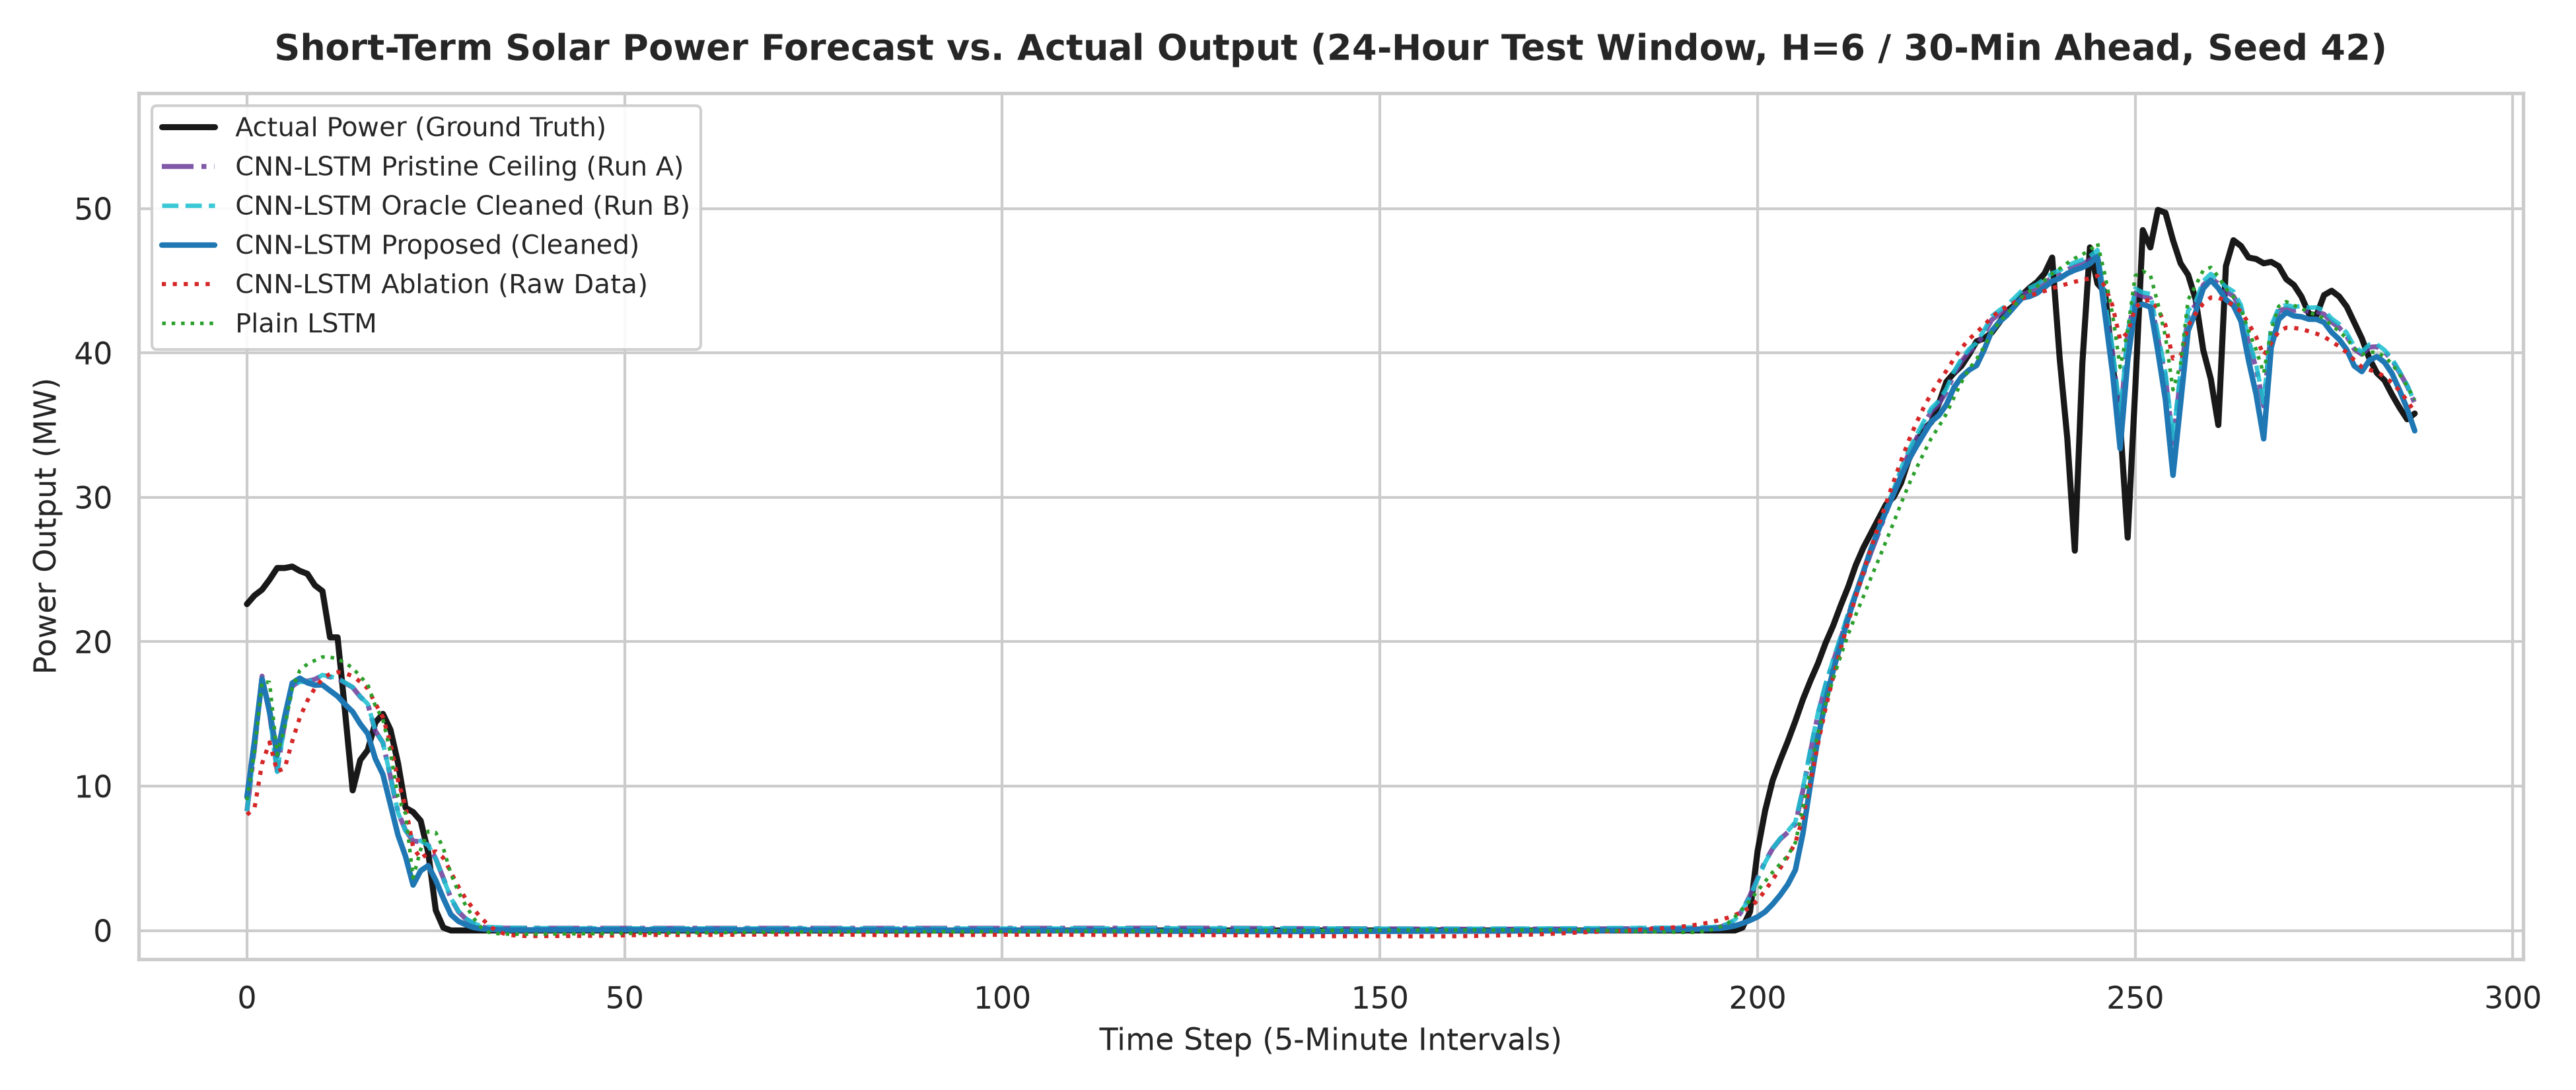

In [9]:
fig, ax = plt.subplots(figsize=(13, 5.5), dpi=300)
sample_len = 288 # 24 hours of 5-min intervals
start_idx = 100
end_idx = start_idx + sample_len

ax.plot(y_test_actual[start_idx:end_idx], label='Actual Power (Ground Truth)', color='black', linewidth=2.2, alpha=0.9)
ax.plot(predictions['CNN-LSTM (Pristine Reference)'][start_idx:end_idx], label='CNN-LSTM Pristine Ceiling (Run A)', color='#6a3d9a', linestyle='-.', linewidth=1.8, alpha=0.85)
ax.plot(predictions['CNN-LSTM (Oracle Cleaned)'][start_idx:end_idx], label='CNN-LSTM Oracle Cleaned (Run B)', color='#17becf', linestyle='--', linewidth=1.6, alpha=0.85)
ax.plot(predictions['CNN-LSTM (Cleaned - Proposed)'][start_idx:end_idx], label='CNN-LSTM Proposed (Cleaned)', color='#1f77b4', linewidth=2.0)
ax.plot(predictions['CNN-LSTM (Raw Data)'][start_idx:end_idx], label='CNN-LSTM Ablation (Raw Data)', color='#d62728', linestyle=':', linewidth=1.5)
ax.plot(predictions['Plain LSTM'][start_idx:end_idx], label='Plain LSTM', color='#2ca02c', linestyle=':', linewidth=1.3)

ax.set_title('Figure 1: Short-Term Solar Power Forecast vs. Actual Output (24-Hour Test Window, H=6 / 30-Min Ahead, Seed 42)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Time Step (5-Minute Intervals)', fontsize=11)
ax.set_ylabel('Power Output (MW)', fontsize=11)
ax.set_ylim(-2, 58)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.92, fontsize=9.5)
plt.tight_layout()
plt.savefig('output/figure1_predicted_vs_actual.png')
plt.show()

## Figure 2: Model Performance Benchmark with Multi-Seed Error Bars (RMSE & MAE across 7 Conditions)
Visualizes the error metric hierarchy across all seven benchmark and ablation models. Error bars represent $\pm 1\text{ Standard Deviation}$ across the 5 training seeds ($yerr = \text{std}$, `capsize=4`), illustrating both predictive accuracy and training stability.

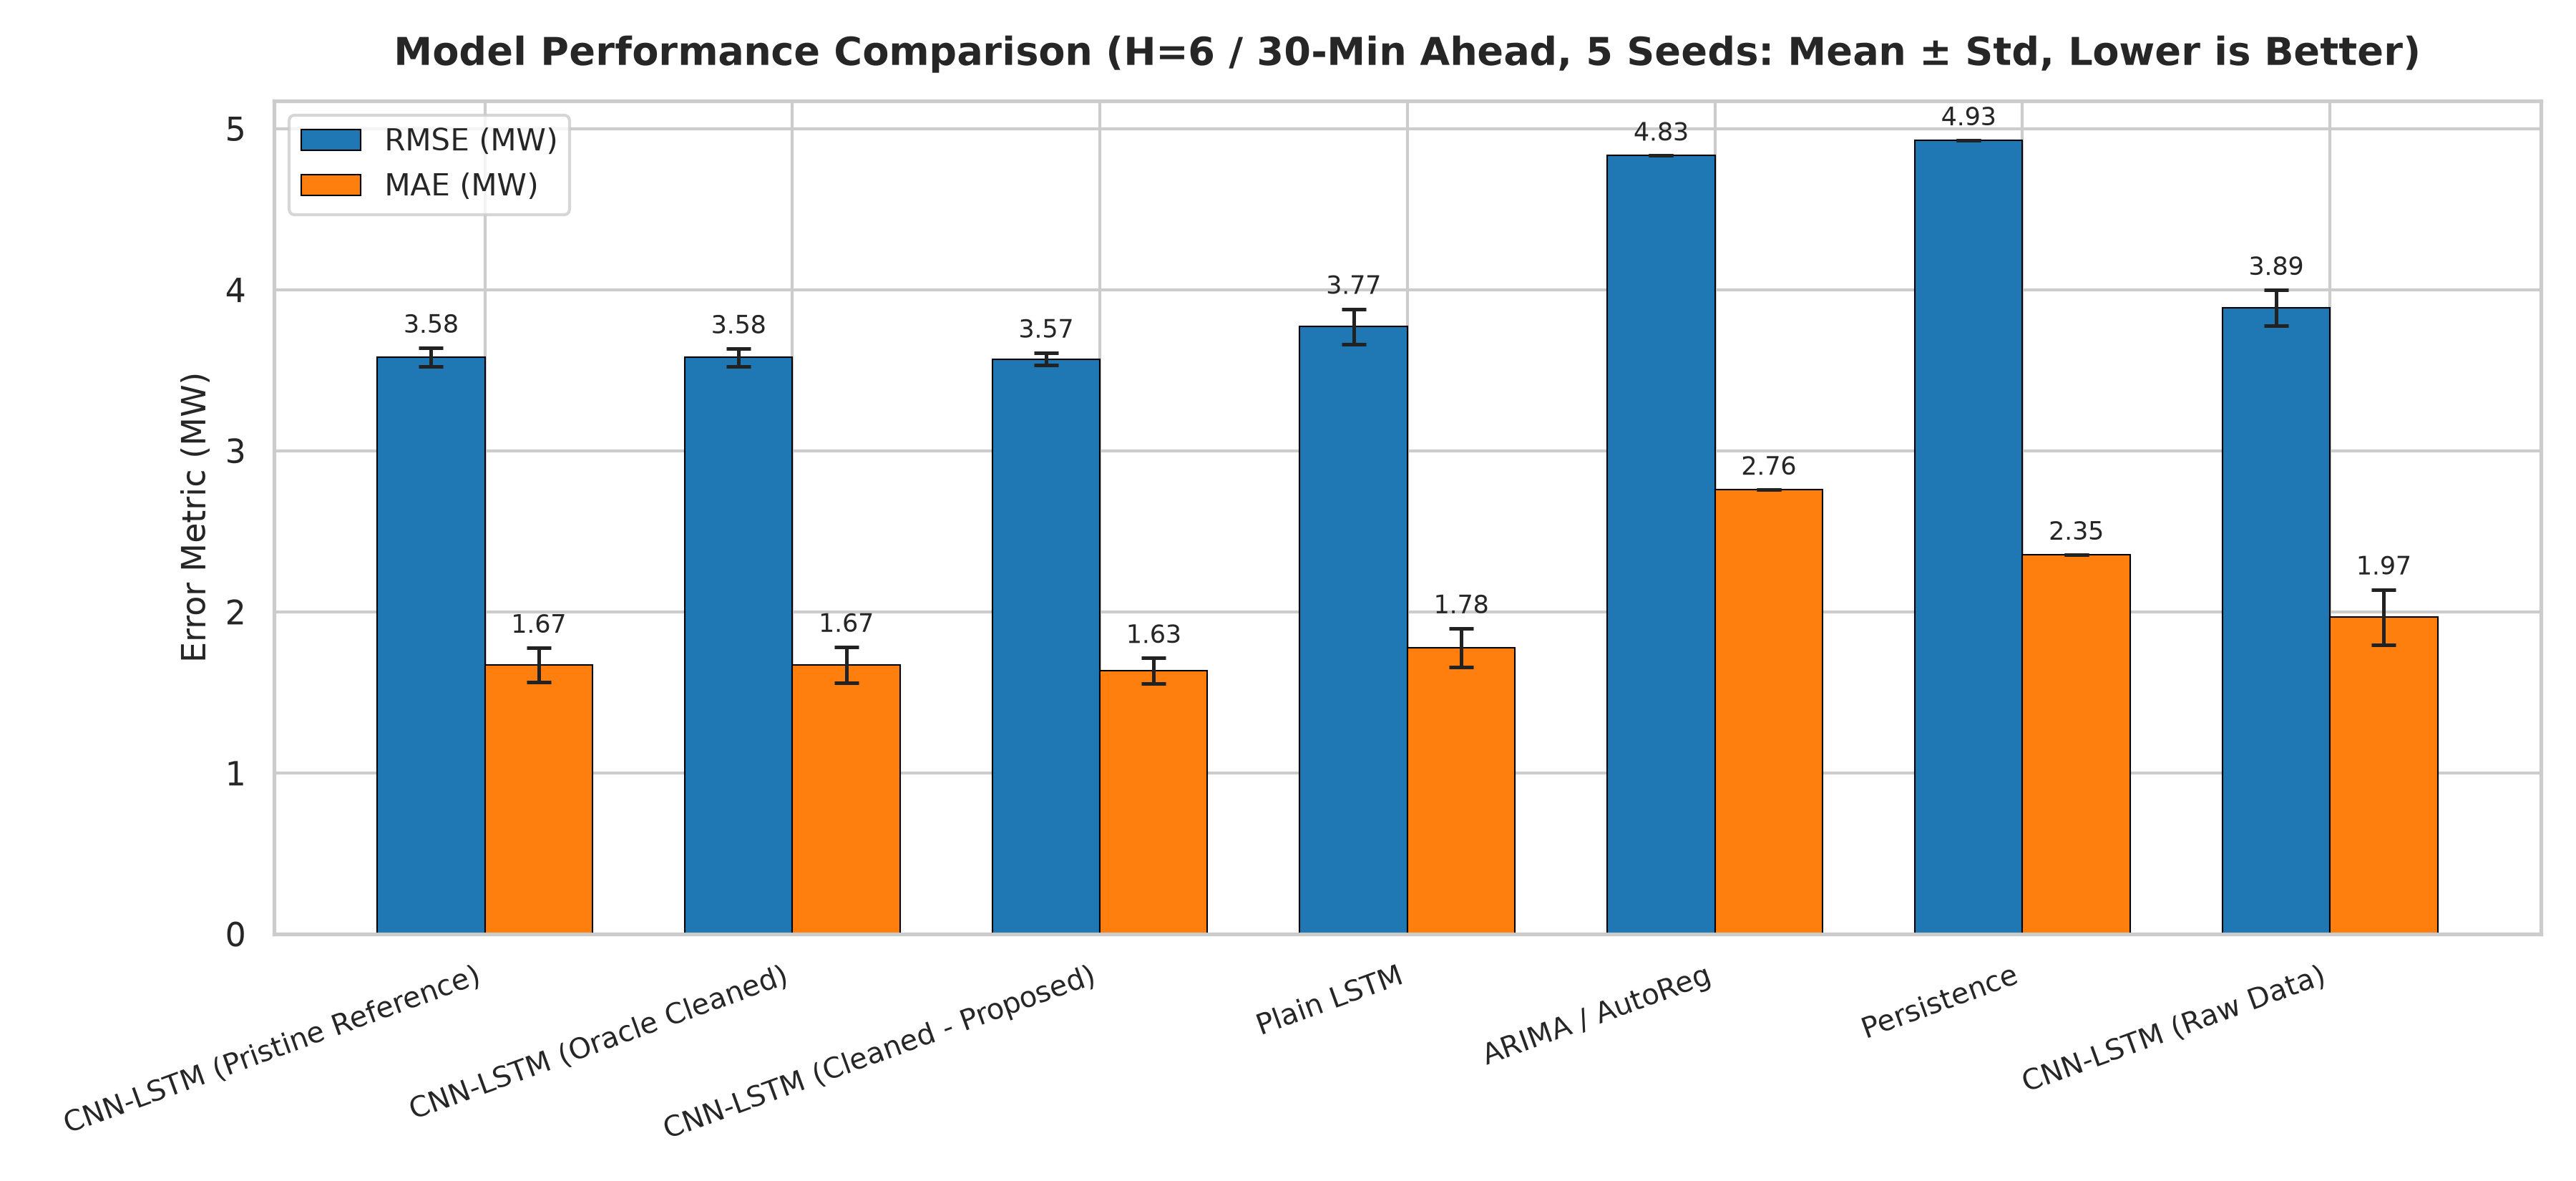

In [10]:
fig, ax = plt.subplots(figsize=(12, 5.5), dpi=300)
models = list(res_df.index)
rmses = [summary_stats[m]['RMSE_mean'] for m in models]
rmses_std = [summary_stats[m]['RMSE_std'] for m in models]
maes = [summary_stats[m]['MAE_mean'] for m in models]
maes_std = [summary_stats[m]['MAE_std'] for m in models]

x = np.arange(len(models))
width = 0.35

rects1 = ax.bar(x - width/2, rmses, width, yerr=rmses_std, capsize=4, label='RMSE (MW)', color='#1f77b4', edgecolor='black', linewidth=0.5, error_kw={'elinewidth': 1.2, 'capthick': 1.2})
rects2 = ax.bar(x + width/2, maes, width, yerr=maes_std, capsize=4, label='MAE (MW)', color='#ff7f0e', edgecolor='black', linewidth=0.5, error_kw={'elinewidth': 1.2, 'capthick': 1.2})

ax.set_title('Figure 2: Model Performance Comparison (H=6 / 30-Min Ahead, 5 Seeds: Mean ± Std, Lower is Better)', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Error Metric (MW)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha='right', fontsize=9.5)
ax.legend(loc='upper left', frameon=True, fontsize=10)

for bar in rects1:
    h = bar.get_height()
    ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)
for bar in rects2:
    h = bar.get_height()
    ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
plt.savefig('output/figure2_rmse_bar_chart.png')
plt.show()

## Figure 3: Residual Error Distribution Histogram (Canonical Seed 42)
Plots the residual error $(\hat{y} - y)$ distribution comparing the proposed CNN-LSTM against the uncleaned raw ablation model and the pristine ceiling.

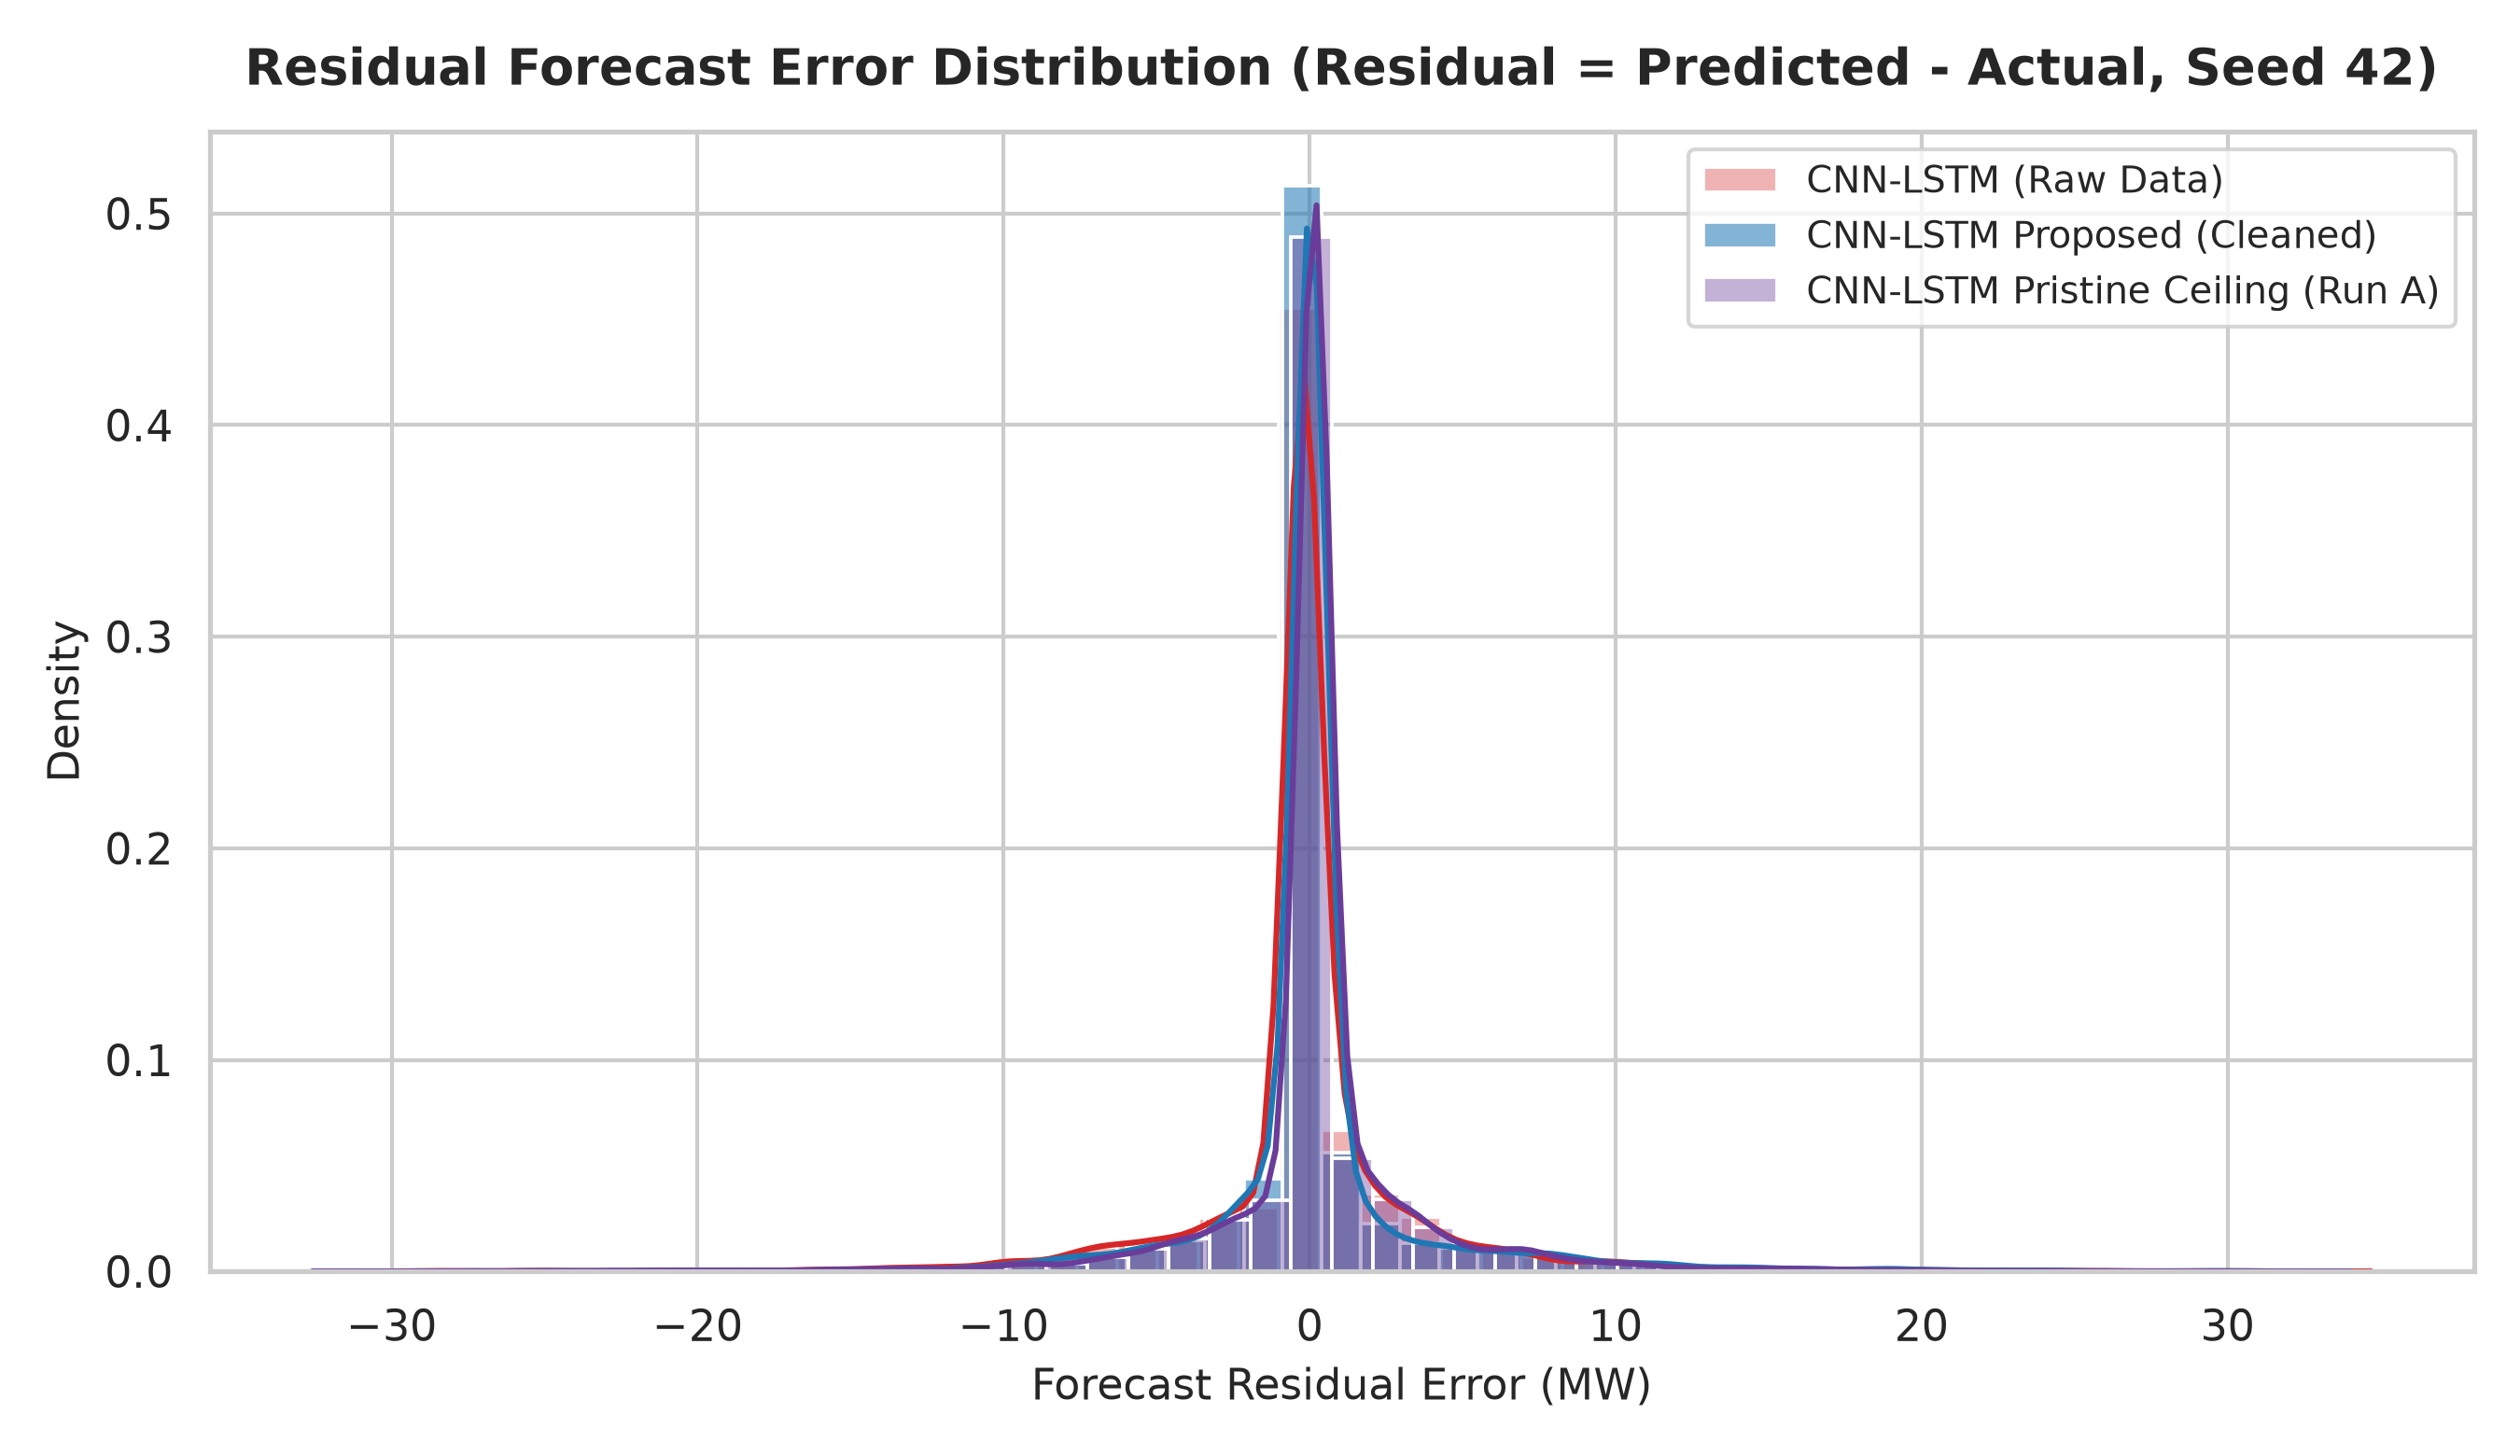

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=300)
prop_err = predictions['CNN-LSTM (Cleaned - Proposed)'] - y_test_actual
raw_err = predictions['CNN-LSTM (Raw Data)'] - y_test_actual
pris_err = predictions['CNN-LSTM (Pristine Reference)'] - y_test_actual

sns.histplot(raw_err, color='#d62728', label='CNN-LSTM (Raw Data)', kde=True, ax=ax, bins=50, stat="density", alpha=0.35)
sns.histplot(prop_err, color='#1f77b4', label='CNN-LSTM Proposed (Cleaned)', kde=True, ax=ax, bins=50, stat="density", alpha=0.55)
sns.histplot(pris_err, color='#6a3d9a', label='CNN-LSTM Pristine Ceiling (Run A)', kde=True, ax=ax, bins=50, stat="density", alpha=0.4)

ax.set_title('Figure 3: Residual Forecast Error Distribution (Residual = Predicted - Actual, Seed 42)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Forecast Residual Error (MW)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig('output/figure3_error_distribution.png')
plt.show()

## Figure 4: Anomaly Detection Demonstration
Visual demonstration of Isolation Forest flagging dropouts and spikes (marked by red 'X's) and local linear interpolation restoring the diurnal curve.

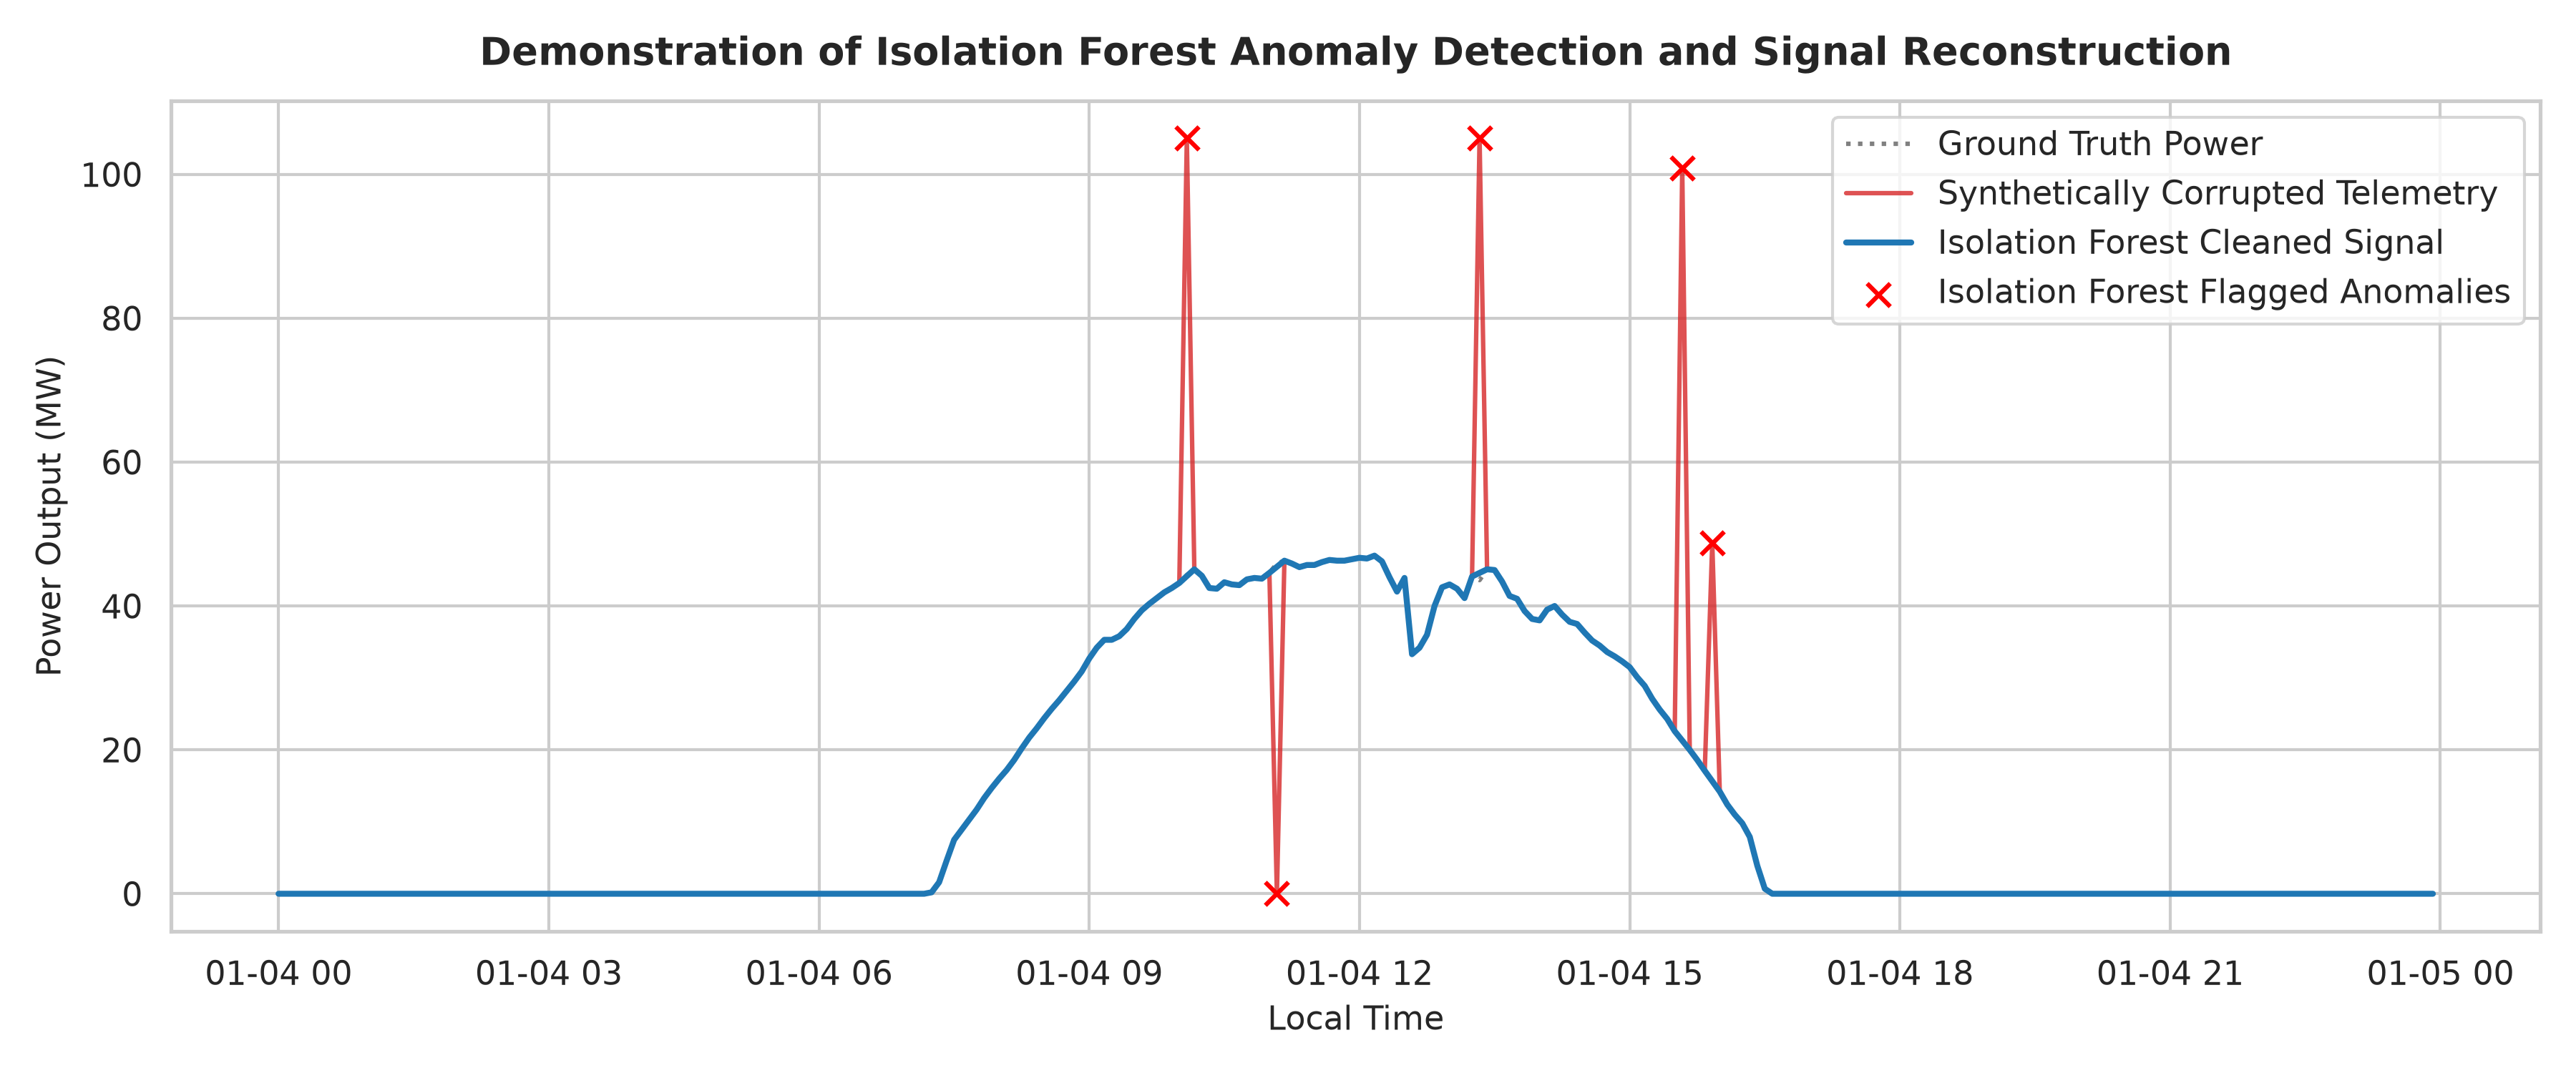

In [12]:
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
anomaly_window = df.iloc[864:1152].copy()

ax.plot(anomaly_window['datetime'], anomaly_window['power_mw'], label='Ground Truth Power', color='gray', linestyle=':', linewidth=1.5)
ax.plot(anomaly_window['datetime'], anomaly_window['power_raw'], label='Synthetically Corrupted Telemetry', color='#d62728', alpha=0.8, linewidth=1.5)
ax.plot(anomaly_window['datetime'], anomaly_window['power_cleaned'], label='Isolation Forest Cleaned Signal', color='#1f77b4', linewidth=2.0)

flagged = anomaly_window[anomaly_window['detected_outlier'] == 1]
if not flagged.empty:
    ax.scatter(flagged['datetime'], flagged['power_raw'], color='red', marker='x', s=60, label='Isolation Forest Flagged Anomalies', zorder=5)

ax.set_title('Figure 4: Demonstration of Isolation Forest Anomaly Detection and Signal Reconstruction', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Local Time', fontsize=11)
ax.set_ylabel('Power Output (MW)', fontsize=11)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig('output/figure4_anomaly_detection_demo.png')
plt.show()